# Phase 2: What Drives Low Hotel Review Scores?

INFO 4360 course project, Phase 2 (development check-in) | Braxton Turner

Problem. A hotel group's guest experience manager needs to know which complaints are behind low review scores, so they can fix the right things first. The data is 515,738 Booking.com reviews of 1,492 hotels in six European cities. Each guest writes what they liked and disliked in two separate boxes.

#### What this notebook covers
1. Data exploration: size, missing values, the score distribution, leakage checks, text length, examples.
2. Text mining: cleaning and noise removal (with NER), keyword frequency, distinctive words (TF-IDF), a first pass at complaint categories, VADER sentiment, and LDA topics.
3. Claude sample prompts: a first test of complaint labeling on 12 reviews.
4. Plan for Phase 3: answers to the design questions from the Phase 1 feedback.

Data used here. `data/hotel_reviews_20k.csv`: 19,998 reviews (19,999 in the file, minus 1 exact duplicate) sampled from the full file, stratified by city and trip type so each group keeps its real share (built by `scripts/make_sample.py`). It keeps the real share of low scores (17.1% vs. 16.8% in the full data), unlike the balanced 2,000-review Phase 1 sample.

#### Changes since Phase 1 (from the feedback)
- `clean_review` is passed to the vectorizers with `preprocessor=clean_review` instead of being applied in separate steps.
- Named entity recognition removes hotel names and staff names as part of the noise removal (Section 2.1).
- VADER is checked by correlating it with the true review score, and neutral scores are split into "no lexicon words" vs. "words cancel out" (Section 2.5).
- The Phase 3 plan moves from predicting low scores to explaining them (Section 4).

## Progress update (Phase 2 check-in)

#### Done since Phase 1
- Built a 19,998-review working sample stratified by city and trip type, keeping the real 17.1% share of low scores (the Phase 1 sample was balanced 50/50).
- Moved the reusable code into `src/` (loading, cleaning, NER noise removal, VADER, complaint categories) so this notebook only calls functions.
- Applied the Phase 1 and Homework 2 feedback: `preprocessor=clean_review` in the vectorizers, NER removal of organization and staff names, VADER correlated with the true score, and the plan changed from predicting low scores to explaining them.
- Finished exploration (Section 1) and text mining (Section 2), then tried the Claude labeling prompt on 12 reviews (Section 3).
- Added a data validation step (Section 1.7): 15 pass/fail checks on row counts, value ranges, placeholders, how well the sample matches the full data, the Claude labels, and the API key. All pass. Writing the checks found two real problems that I fixed: about 130 "nothing to dislike"-type placeholders counted as complaints, and 1 duplicate review.

#### What I've found so far
- How often a complaint shows up and how many points it costs are different things. Breakfast is the most common complaint but costs almost nothing (under 0.1 points). Cleanliness costs about 1.3 points, and staff complaints are both common and costly (about 1.1 points).
- Business travelers give low scores more often than leisure travelers (24.6% vs. 15.5%), and nationality moves the average by up to 0.9 points. Both go into the Phase 3 model as controls.
- VADER tracks the score only weakly (r = 0.28 and 0.36), and about 30% of complaints contain no VADER lexicon word at all. That is why the plan uses Claude labels, which come with evidence quotes.
- SpaCy NER mistook complaint words ("Breakfast", "AC", "Wifi") for names, so I changed the removal to work word by word. LDA topics showed a missing category, so I added `facilities` and widened `checkin` and `value`.

#### What's left for Phase 3
- Label about 3,000 stratified reviews with Claude through the Batch API, and hand-check about 100 of those labels.
- Fit the score regression with controls, build the fix list (coefficient × frequency), and check it separately for business vs. leisure travelers and by city.
- Compare against a TF-IDF model on out-of-sample R².

Open risks: whether Claude labels hold up in the hand check, and that review length could be standing in for complaint type (handled with a word-count control, Section 4).

## 0. Setup

In [1]:
# Step 0: Imports. Reusable functions live in src/ so the notebook stays readable.
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # repo root, so `import src...` works from notebooks/

import collections
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import LatentDirichletAllocation
from wordcloud import WordCloud

from src.data import load_reviews
from src.preprocessing import clean_review, STOP_WORDS, load_ner, denoise, common_lowercase_words
from src.sentiment import vader_table
from src.complaints import CATEGORIES, keyword_flags, prompt_label, label_with_cache

pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
LOW, HIGH = "#c0392b", "#2c7fb8"   # colors for low-score and high-score reviews

## 1. Data Exploration

### 1.1 Basic stats

In [2]:
# Step 1.1: Load the sample. load_reviews() also turns placeholders like "No Negative" or "nothing"
# into empty text (neg_text / pos_text) and adds has_neg / has_pos flags and word counts.
n_file = len(pd.read_csv(Path.cwd().parent / "data" / "hotel_reviews_20k.csv"))
df = load_reviews()   # data/hotel_reviews_20k.csv
print(n_file, ">>", len(df), "rows (exact duplicates dropped)")
assert n_file - len(df) == 1, "expected to drop 1 exact duplicate row"
assert df.Review_Date.notna().all() and df.Reviewer_Score.between(2.5, 10).all()
assert (df.Low_Score == (df.Reviewer_Score < 7)).all()
print(f"{len(df):,} reviews | {df.Hotel_Name.nunique():,} hotels | {df.City.nunique()} cities | "
      f"{df.Review_Date.min():%b %Y} to {df.Review_Date.max():%b %Y}")
print("\nMissing values per column:")
print(df[["Hotel_Name", "City", "Review_Date", "Reviewer_Nationality", "Trip_Type", "Nights",
          "Negative_Review", "Positive_Review", "Reviewer_Score"]].isna().sum().to_string())

19999 >> 19998 rows (exact duplicates dropped)
19,998 reviews | 1,434 hotels | 6 cities | Aug 2015 to Aug 2017

Missing values per column:
Hotel_Name               0
City                     0
Review_Date              0
Reviewer_Nationality     0
Trip_Type                0
Nights                  10
Negative_Review          0
Positive_Review          0
Reviewer_Score           0


In [3]:
# How many review boxes are placeholders rather than real text?
placeholders = pd.DataFrame({
    "box is empty or a placeholder": [1 - df.has_neg.mean(), 1 - df.has_pos.mean()],
    "most common placeholder": [df.loc[df.has_neg == 0, "Negative_Review"].str.strip().value_counts().index[0],
                                df.loc[df.has_pos == 0, "Positive_Review"].str.strip().value_counts().index[0]],
}, index=["Negative box", "Positive box"])
placeholders.style.format({"box is empty or a placeholder": "{:.1%}"})

,box is empty or a placeholder,most common placeholder
Negative box,31.3%,No Negative
Positive box,7.5%,No Positive


What I see. The sample has 19,998 reviews (one exact duplicate row is dropped) of 1,434 hotels in 6 cities, from Aug 2015 to Aug 2017. Almost nothing is missing; only `Nights` is blank for 10 reviews, whose tags don't say how long they stayed. The real gap is hidden: 31.3% of negative boxes and 7.5% of positive boxes are placeholders, mostly Booking.com's "No Negative" / "No Positive", plus guest-typed versions like "nothing", "n a", "none", "nothing to dislike" and "everything was perfect" (I found these by listing the most common short complaints; they all came with high scores). If I left them in, "negative" and "no" would be among the top complaint words and VADER would score "No Negative" as a complaint. `load_reviews()` turns them into empty text and keeps a `has_neg` flag instead.

### 1.2 Target: the review score

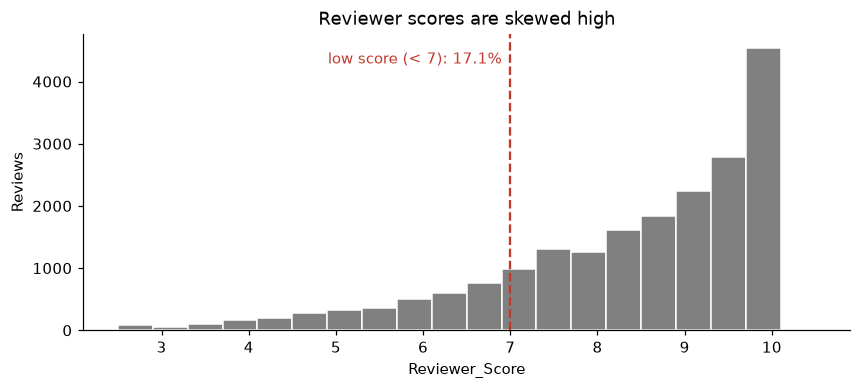

count    19998.00
mean         8.40
std          1.64
min          2.50
25%          7.50
50%          8.80
75%          9.60
max         10.00


In [4]:
# Step 1.2: Score distribution and the share of low scores (below 7)
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df.Reviewer_Score, bins=np.arange(2.5, 10.6, 0.4), color="gray", edgecolor="white")
ax.axvline(7, color=LOW, ls="--")
ax.text(6.9, ax.get_ylim()[1] * 0.9, f"low score (< 7): {df.Low_Score.mean():.1%}", ha="right", color=LOW)
ax.set(title="Reviewer scores are skewed high", xlabel="Reviewer_Score", ylabel="Reviews")
plt.show()
print(df.Reviewer_Score.describe().round(2).to_string())

In [5]:
# Low-score share by city and by trip type
by_city = df.groupby("City").agg(reviews=("Low_Score", "size"), low_share=("Low_Score", "mean"),
                                 mean_score=("Reviewer_Score", "mean")).sort_values("low_share")
by_trip = df.groupby("Trip_Type").agg(reviews=("Low_Score", "size"), low_share=("Low_Score", "mean"),
                                      mean_score=("Reviewer_Score", "mean")).sort_values("low_share")
fmt = {"low_share": "{:.1%}", "mean_score": "{:.2f}"}
display(by_city.style.format(fmt), by_trip.style.format(fmt))

,reviews,low_share,mean_score
City,,,
Vienna,1510,13.1%,8.55
Barcelona,2332,15.4%,8.49
Paris,2322,16.3%,8.46
Amsterdam,2219,16.5%,8.44
Milan,1444,17.4%,8.38
London,10171,18.3%,8.33


,reviews,low_share,mean_score
Trip_Type,,,
Leisure,16200,15.5%,8.48
Unknown,582,19.4%,8.18
Business,3216,24.6%,8.00


What I see. Scores are skewed high: mean 8.40, median 8.8, and only 17.1% are below 7. The low-score rate varies by city, from 13.1% in Vienna to 18.3% in London, but the bigger difference is trip type: 24.6% of business travelers give a low score vs. 15.5% of leisure travelers (mean 8.00 vs. 8.48). So business and leisure guests are not the same audience, and Phase 3 has to (1) control for trip type and city and (2) check whether the complaint ranking is the same for both groups, as the feedback suggested. London is half the sample (10,171 reviews), so pooled results will lean toward London unless city is controlled.

### 1.3 Leakage checks

In [6]:
# Step 1.3a: Average_Score is the hotel's average of these same review scores, so it partly contains the answer
print("Correlation of Average_Score with Reviewer_Score:", round(df.Average_Score.corr(df.Reviewer_Score), 3))

# Step 1.3b: Did the guest write anything in the negative box?
pd.crosstab(df.has_neg.map({0: "no complaint written", 1: "complaint written"}),
            df.Low_Score.map({0: "high score", 1: "low score"}), normalize="columns").style.format("{:.1%}")

Correlation of Average_Score with Reviewer_Score: 0.368


Low_Score,high score,low score
has_neg,,
complaint written,62.9%,96.9%
no complaint written,37.1%,3.1%


#### Leakage checks (from Phase 1)
- `Average_Score` correlates 0.37 with the review score. It is the hotel's average of these same scores, so it partly contains the answer, and "be a better hotel" is not something the manager can act on. It is excluded from all models.
- The empty negative box is almost a label by itself: 96.9% of low-score reviews wrote a complaint, compared with 62.9% of high-score reviews. Not writing anything is not something a hotel can fix, so I treat it as a flag, not a driver. Reviews with no complaint get all complaint flags = 0 for free (no API call), and they are the baseline the complaint coefficients are compared against.

### 1.4 Reviewer nationality

In [7]:
# Step 1.4: Do some nationalities rate lower? Top 10 nationalities by number of reviews
nat = (df.groupby("Reviewer_Nationality")
         .agg(reviews=("Reviewer_Score", "size"), mean_score=("Reviewer_Score", "mean"), low_share=("Low_Score", "mean"))
         .sort_values("reviews", ascending=False).head(10))
nat.style.format({"mean_score": "{:.2f}", "low_share": "{:.1%}"})

,reviews,mean_score,low_share
Reviewer_Nationality,,,
United Kingdom,9543,8.48,16.2%
United States of America,1363,8.77,11.7%
Australia,810,8.57,13.6%
Ireland,548,8.51,15.9%
United Arab Emirates,409,7.88,25.7%
Saudi Arabia,352,8.02,24.1%
Switzerland,346,8.18,21.4%
Canada,328,8.51,14.9%
France,320,8.11,20.9%


What I see. Nationality matters a lot: guests from the United Arab Emirates average 7.88 (25.7% low) and Saudi Arabia 8.02 (24.1% low), while US guests average 8.77 (11.7% low). That is a gap of almost 0.9 points, bigger than most of the complaint gaps in Section 2.4. It probably reflects different rating habits and expectations, not different hotels. As the feedback said, nationality goes into the Phase 3 model as a control (top 15 nationalities + "other"), not as a finding about a group. Nationality mix also differs by city (UK guests are a large share of London reviews), so without this control some of the city differences would really be nationality differences.

### 1.5 Text length

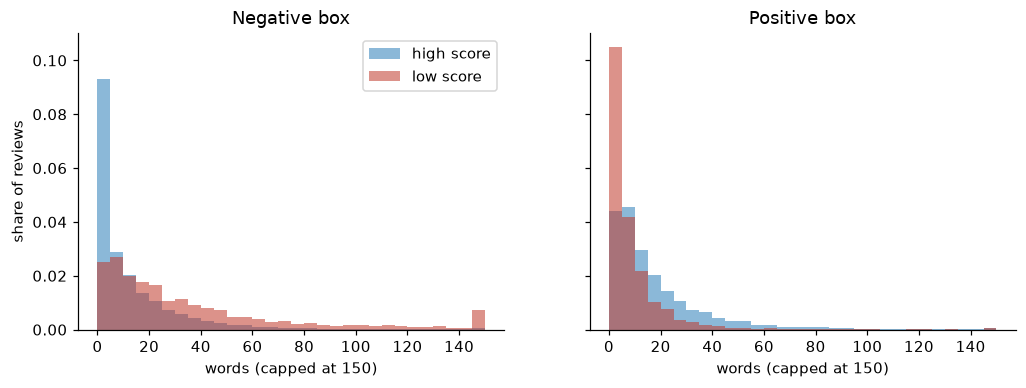

Median words:
            neg_words  pos_words
Low_Score                       
high score        5.0       11.0
low score        22.0        4.0

Correlation with Reviewer_Score: negative words -0.377 | positive words 0.211


In [8]:
# Step 1.5: Word counts of the negative and positive text (placeholders count as 0 words)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, side in zip(axes, ["neg", "pos"]):
    for low, color, label in [(0, HIGH, "high score"), (1, LOW, "low score")]:
        words = df.loc[df.Low_Score == low, f"{side}_words"].clip(upper=150)
        ax.hist(words, bins=30, color=color, alpha=0.55, density=True, label=label)
    ax.set(title=f"{'Negative' if side == 'neg' else 'Positive'} box", xlabel="words (capped at 150)")
axes[0].set_ylabel("share of reviews"); axes[0].legend()
plt.show()

length = df.groupby(df.Low_Score.map({0: "high score", 1: "low score"}))[["neg_words", "pos_words"]].median()
print("Median words:"); print(length.to_string())
print("\nCorrelation with Reviewer_Score: negative words",
      round(df.neg_words.corr(df.Reviewer_Score), 3), "| positive words", round(df.pos_words.corr(df.Reviewer_Score), 3))

What I see. Length is a strong signal on its own. Low-score reviews have a median of 22 words in the negative box vs. 5 for high-score reviews, and only 4 words of praise vs. 11. Negative word count correlates -0.38 with the score, about as strong as anything else in this notebook. This matters for Phase 3: a TF-IDF model will pick up how much a guest complained, not only what they complained about. So I will report the category model with and without a word-count control. If a complaint's coefficient holds up with the control, it is not just a proxy for a long, angry review.

### 1.6 Examples

In [9]:
# Step 1.6: Three random low-score and three random high-score reviews
# Drawn with groupby("Low_Score").sample(3, random_state=4360) in the first run; ids kept so the text below matches
examples = df.loc[[4524, 3360, 8745, 657, 3832, 2199]]
examples[["City", "Trip_Type", "Reviewer_Score", "Negative_Review", "Positive_Review"]]

,City,Trip_Type,Reviewer_Score,Negative_Review,Positive_Review
4524,Barcelona,Unknown,8.8,No fresh orange juice available at breakfast,Its location very close to the Conference centre and to public transport In general staff friendly and helpful
3360,Barcelona,Leisure,8.8,The wifi connection is not that great but it worked,Breakfast was great staff extremely helpful
8745,London,Leisure,7.9,Although breakfast was nice it would be nice to have some vegetarian options,Great location ideal for Hyde park concerts Lovely room Good car park would recommend to anyone wanting to go to Lo...
657,Amsterdam,Leisure,5.8,Checked in to an occupied room long waiting at check in and out no staff Breakfast was a shambles For the first tim...,No Positive
3832,Barcelona,Leisure,3.8,Not much to like about this hotel and for the price I paid per night I would definitely not recommend this hotel to...,Not much to like about this hotel and for the price I paid per night I would definitely not recommend this hotel to...
2199,Amsterdam,Unknown,2.5,We wanted to stay two nights in Amsterdam Booked Savoy as 4 star hotel Drop our luggage in the room and enjoyed Ams...,No Positive


What I see. High-score complaints are small wishes: "No fresh orange juice available at breakfast", "wifi connection is not that great but it worked", "it would be nice to have some vegetarian options". Low-score complaints are lists of failures: an occupied room at check-in, long waits, "Breakfast was a shambles". One more thing: review 3832 pasted the same complaint ("Not much to like about this hotel...") into both boxes, so the positive box is not always praise. Labeling each box with Claude, rather than assuming its polarity, handles this.

### 1.7 Data validation

Before the text mining, `run_validation()` (in `src/validation.py`) checks the cleaned data with the three test habits from INFO 4340: row counts (where did every row go?), data descriptions (are the values plausible?) and code logic (recompute a number a second way). Each check passes or fails, so a problem can't hide in a chart. The two sampling checks compare against the full 515K file, which is kept outside the repo; without it they show SKIP.

In [10]:
# Step 1.7: Pass/fail checks on the cleaned data
from src.validation import run_validation

df_raw = pd.read_csv(Path.cwd().parent / "data" / "hotel_reviews_20k.csv")
validation = run_validation(df_raw, df,
                            labels_path=Path.cwd().parent / "data" / "claude_sample_labels.jsonl",
                            full_path=Path.home() / "datasets" / "hotel_reviews_515k" / "Hotel_Reviews.csv")
print((validation.result == "PASS").sum(), "of", len(validation), "checks passed")
assert not (validation.result == "FAIL").any(), "a validation check failed"
validation

15 of 15 checks passed


,check,result,detail
0,Row count: only the 1 duplicate dropped,PASS,"19,999 >> 19,998"
1,No duplicate rows or ids,PASS,0 duplicate rows
2,Scores in 2.5-10,PASS,2.5 to 10.0
3,Low_Score = score below 7,PASS,recomputed from the score
4,"Dates parsed, Aug 2015 to Aug 2017",PASS,0 missing dates
5,City and Trip_Type valid,PASS,"6 cities, 3 trip types"
6,"Nights: 10 missing, all others >= 1",PASS,"10 missing, max 27.0"
7,Placeholder boxes are empty text with 0 words,PASS,"6,260 negative placeholders"
8,No placeholder counted as a complaint,PASS,0 leaks
9,Every city x trip group within 0.1 pp of the full data,PASS,largest gap 0.006 pp


What I see. All checks pass. The only rows dropped are 1 exact duplicate, every city x trip-type group in the sample is within 0.006 percentage points of its share in the full data, and the low-score share is within 0.23 points. No placeholder ("No Negative", "nothing to dislike") is counted as a complaint. An earlier version of this check found about 130 of them slipping through, which is why `NO_CONTENT` in `src/data.py` has a longer list now.

## 2. Text Mining

### 2.1 Cleaning and noise removal with NER

Two steps, both in `src/preprocessing.py`:
1. Noise removal (before vectorizing): remove the reviewed hotel's own name, then use spaCy NER to remove other organizations (`ORG`: other hotels, chains, brands) and people (`PERSON`: staff names, which are also personal information). Names say nothing about what went wrong.
2. `clean_review` (inside the vectorizer): lowercase, letters only. It is passed as `preprocessor=clean_review`, and the vectorizer then drops stop words, but keeps negations like not, no, and nothing.

A problem came up when I first ran NER: Booking.com strips all punctuation, so the first word of each sentence is capitalized and has no period before it. spaCy then tags ordinary words as names: "Breakfast", "Shower", and "Bathroom" became `ORG`, and "Pillows" and "Wifi" became `PERSON`. "AC" (air conditioning) was removed 88 times, and "Kensington High Street Bed" was removed as one entity, taking the complaint word "Bed" with it. Removing all `ORG` entities would delete the complaints themselves.

So the removal works word by word inside each entity. A word is kept if it is lowercase in the review, if guests write it in lowercase at least 5 times elsewhere in the corpus (so it is an ordinary word), or if it is an amenity acronym (AC, TV, WC). Only the rare capitalized words (hotel brands and people's names) are removed.

In [11]:
# Step 2.1: Run NER noise removal on both boxes (about a minute on 20K reviews)
nlp = load_ner()
common = common_lowercase_words(list(df.neg_text) + list(df.pos_text))
df["neg_clean"], neg_removed, neg_kept = denoise(df, "neg_text", nlp, common)
df["pos_clean"], pos_removed, pos_kept = denoise(df, "pos_text", nlp, common)

removed = collections.Counter(neg_removed + pos_removed)
kept = collections.Counter(neg_kept + pos_kept)
print(f"Entities removed: {sum(removed.values()):,} | one-word entities kept as ordinary words: {sum(kept.values()):,}\n")
pd.DataFrame({"removed (entity, label)": [f"{t} ({l}): {n}" for (t, l), n in removed.most_common(15)],
              "kept as ordinary words": [f"{t} ({l}): {n}" for (t, l), n in kept.most_common(15)]})

Entities removed: 2,740 | one-word entities kept as ordinary words: 8,693



,"removed (entity, label)",kept as ordinary words
0,Euston (PERSON): 27,Hotel (ORG): 563
1,DLR (ORG): 26,Location (ORG): 320
2,Kensington (ORG): 23,the (ORG): 210
3,Albert (PERSON): 22,Breakfast (ORG): 142
4,Earls (ORG): 19,Rooms (ORG): 138
5,Milan (ORG): 19,Wifi (PERSON): 131
6,Eurostar (ORG): 17,Nice (ORG): 124
7,Earl (ORG): 17,WiFi (PERSON): 111
8,Catalunya (PERSON): 16,AC (ORG): 95
9,Victoria (PERSON): 16,Breakfast (PERSON): 85


In [12]:
# Before and after for a few reviews where something was removed
changed = df[(df.neg_clean != df.neg_text) & (df.neg_words.between(8, 40))].sample(4, random_state=1)
for row in changed.itertuples():
    print(f"[{row.Hotel_Name}]\n  before: {row.neg_text}\n  after:  {row.neg_clean}\n  vectorizer sees: {clean_review(row.neg_clean)}\n")

[Novotel Suites Paris Expo Porte de Versailles]
  before: Poor breakfast 25 mins of the Avenue des Champs lys es by metro
  after:  Poor breakfast 25 mins of the des Champs lys es by metro
  vectorizer sees: poor breakfast mins of the des champs lys es by metro

[citizenM London Shoreditch]
  before: Location was great for Shoreditch but a bit of a walk to the nearest tube station at Liverpool St
  after:  Location was great for but a bit of a walk to the nearest tube station at St
  vectorizer sees: location was great for but a bit of a walk to the nearest tube station at st

[Best Western Hotel Ascot]
  before: Absolutely terrible breakfast Also we sat through breakfast watching the waiter flicking crumbs etc off tables onto the floor and resetting the table for new guests Yuck
  after:  Absolutely terrible breakfast Also we sat through breakfast watching the waiter flicking crumbs etc off tables onto the floor and resetting the table for new guests
  vectorizer sees: absolutely terr

What I see. After the word-by-word rule, 2,740 words were removed and 8,693 words that spaCy tagged as entities were kept as ordinary words ("Hotel", "Location", "Breakfast", "Wifi", "AC", "Shower"). The removed words are mostly place names that spaCy mislabels as `ORG` or `PERSON` (Euston, Kensington, Victoria, Sagrada, Elysees), hotel and transport brands (Eurostar, DLR), and staff first names. Place and brand names don't tell me the type of complaint, so removing them is fine. Staff names are personal information, so removing them is a privacy step before any text goes to the Claude API.

The feedback suggested removing all organization names. On this data, doing that blindly would have deleted the complaint words, so the before/after check was worth doing. It isn't perfect: it leaves fragments like "des Champs", and the few non-English reviews get mangled. That doesn't affect the complaint categories.

### 2.2 Keyword frequency

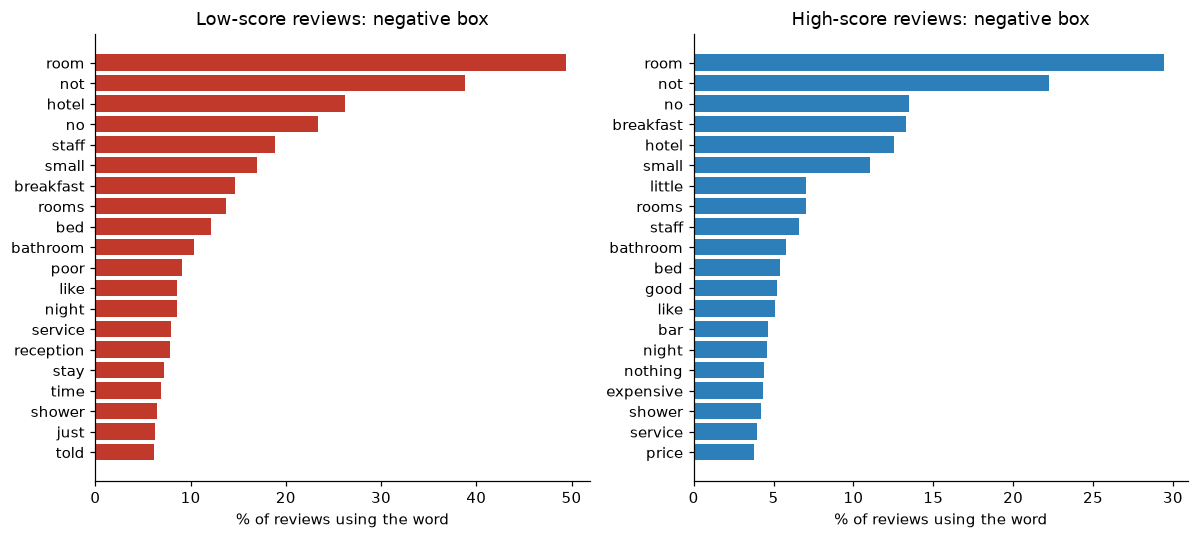

In [13]:
# Step 2.2: Top words in the NEGATIVE box, low-score vs. high-score reviews.
# clean_review is passed as the preprocessor, so cleaning, tokenizing and stop words happen in one step.
def top_terms(texts, n=20, ngram_range=(1, 1)):
    vec = CountVectorizer(preprocessor=clean_review, stop_words=STOP_WORDS, ngram_range=ngram_range, min_df=5)
    counts = vec.fit_transform(texts)
    share = np.asarray((counts > 0).mean(axis=0)).ravel()           # share of reviews that use the term
    return pd.Series(share, index=vec.get_feature_names_out()).nlargest(n)

has_neg = df[df.has_neg == 1]
low_neg = has_neg.loc[has_neg.Low_Score == 1, "neg_clean"]
high_neg = has_neg.loc[has_neg.Low_Score == 0, "neg_clean"]

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, texts, color, title in [(axes[0], low_neg, LOW, "Low-score reviews"), (axes[1], high_neg, HIGH, "High-score reviews")]:
    top = top_terms(texts)
    ax.barh(top.index[::-1], top.values[::-1] * 100, color=color)
    ax.set(title=f"{title}: negative box", xlabel="% of reviews using the word")
plt.tight_layout(); plt.show()

In [14]:
# Two-word phrases are easier to act on than single words
low_bi = top_terms(low_neg, 15, (2, 2))
high_bi = top_terms(high_neg, 15, (2, 2))
pd.DataFrame({"low-score: top bigrams": low_bi.index, "% (low)": (low_bi.values * 100).round(1),
              "high-score: top bigrams": high_bi.index, "% (high)": (high_bi.values * 100).round(1)})

,low-score: top bigrams,% (low),high-score: top bigrams,% (high)
0,room small,4.7,room small,2.6
1,room not,4.4,room not,1.6
2,star hotel,2.9,room service,1.5
3,air conditioning,2.6,not good,1.5
4,not clean,2.6,air conditioning,1.2
5,not good,2.3,tea coffee,1.2
6,booking com,2.2,small room,1.1
7,small room,2.2,breakfast not,1.1
8,staff not,2.1,rooms small,0.9
9,not working,2.0,room no,0.7


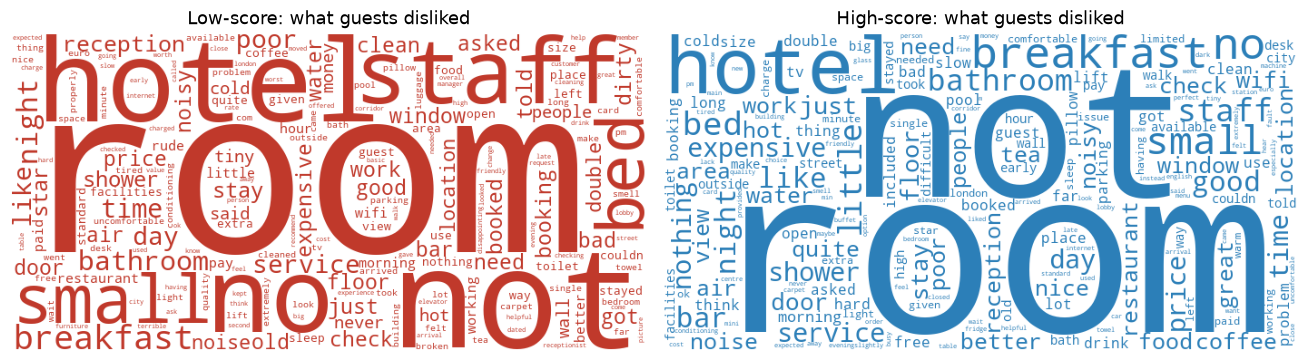

In [15]:
# Word clouds of the negative box: low-score vs. high-score reviews
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, texts, color, title in [(axes[0], low_neg, LOW, "Low-score: what guests disliked"),
                                (axes[1], high_neg, HIGH, "High-score: what guests disliked")]:
    text = " ".join(texts.map(clean_review))
    cloud = WordCloud(width=700, height=350, background_color="white", stopwords=set(STOP_WORDS),
                      color_func=lambda *args, color=color, **kwargs: color,
                      collocations=False, random_state=1).generate(text)
    ax.imshow(cloud); ax.axis("off"); ax.set_title(title)
plt.tight_layout(); plt.show()

What I see. Both groups mention "room", "not" and "hotel" most, so single-word counts mostly show what is common, not what is bad. The differences are in the next words. Low-score complaints are about service failures: "staff" (19% of low-score complaints vs. about 7% of high-score), "poor", "reception", "told", "service", "night". High-score complaints are minor annoyances and price: "breakfast" (13%), "little", "nothing", "bar", "expensive", "price". Bigrams are easier to act on: "not clean" (2.6% of low-score complaints, not in the high-score top 15), "staff not", "not working", "not worth" vs. "tea coffee", "mini bar", "breakfast included" for high scores. Keeping negations in the stop-word list matters here: without "not", "not clean" would become "clean".

### 2.3 Distinctive words (TF-IDF)

TF-IDF vocabulary: 1,858 words from 13,738 negative reviews


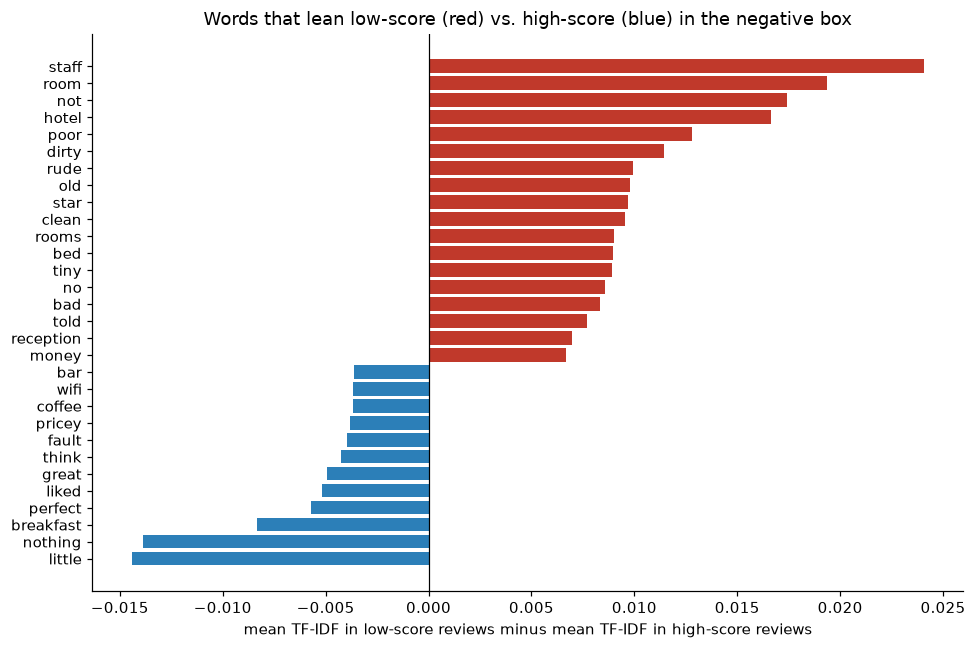

In [16]:
# Step 2.3: Which words separate low-score from high-score negative reviews?
# Mean TF-IDF weight in low-score reviews minus mean weight in high-score reviews.
tfidf = TfidfVectorizer(preprocessor=clean_review, stop_words=STOP_WORDS, min_df=10, sublinear_tf=True)
X = tfidf.fit_transform(has_neg.neg_clean)
is_low = (has_neg.Low_Score == 1).to_numpy()
gap = pd.Series(np.asarray(X[is_low].mean(axis=0) - X[~is_low].mean(axis=0)).ravel(),
                index=tfidf.get_feature_names_out())
print(f"TF-IDF vocabulary: {len(gap):,} words from {X.shape[0]:,} negative reviews")

fig, ax = plt.subplots(figsize=(9, 6))
words = pd.concat([gap.nsmallest(12), gap.nlargest(18)[::-1]])
ax.barh(words.index, words.values, color=[LOW if v > 0 else HIGH for v in words.values])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Words that lean low-score (red) vs. high-score (blue) in the negative box",
       xlabel="mean TF-IDF in low-score reviews minus mean TF-IDF in high-score reviews")
plt.tight_layout(); plt.show()

What I see. TF-IDF on the 13,738 real complaints (1,858-word vocabulary) gives the same picture with sharper words. Words that lean low-score: staff, poor, dirty, rude, old, tiny, bad, told, reception. Words that lean high-score: nothing, little, breakfast, perfect, liked, great, pricey, fault (as in "no fault").

This is what the feedback predicted: TF-IDF largely measures how strongly a guest complains. Words like "poor", "bad", "rude", and "tiny" vs. "little" and "pricey" are about intensity and tone. "Nothing", "perfect" and "liked" are softeners that happy guests use even in the complaint box. That makes TF-IDF a good benchmark for how much of the score text can explain. But it is a poor fix list: "poor" and "bad" do not tell a manager what to fix.

### 2.4 First pass at complaint categories (keyword lexicon)

Before paying for any labels, a simple keyword lexicon (`src/complaints.py`) gives a rough idea of how often each complaint shows up and how much lower the score is when it does. It is only a first pass: it counts "clean" in "not clean", and "hot" in "no hot water". Claude labels replace it in Phase 3.

In [17]:
# Step 2.4: For each category, how common it is and the score gap when it is mentioned
flags = keyword_flags(has_neg.neg_clean)
rows = []
for cat in flags:
    mentioned = flags[cat] == 1
    rows.append({"category": cat,
                 "% of complaints mentioning": mentioned.mean() * 100,
                 "% among low-score": mentioned[has_neg.Low_Score == 1].mean() * 100,
                 "% among high-score": mentioned[has_neg.Low_Score == 0].mean() * 100,
                 "mean score if mentioned": has_neg.Reviewer_Score[mentioned].mean(),
                 "mean score if not": has_neg.Reviewer_Score[~mentioned].mean()})
cats = pd.DataFrame(rows).set_index("category")
cats["score gap"] = cats["mean score if mentioned"] - cats["mean score if not"]
cats = cats.sort_values("score gap")
cats.style.format("{:.1f}").format("{:+.2f}", subset="score gap").background_gradient("Reds_r", subset="score gap")

,% of complaints mentioning,% among low-score,% among high-score,mean score if mentioned,mean score if not,score gap
category,,,,,,
cleanliness,7.7,16.4,4.9,6.7,8.0,-1.32
staff,16.9,30.7,12.5,7.0,8.1,-1.08
checkin,7.9,14.0,6.0,7.1,8.0,-0.91
bed_comfort,10.3,16.8,8.3,7.2,8.0,-0.82
maintenance,12.8,21.1,10.2,7.2,8.0,-0.82
noise,8.6,12.6,7.3,7.4,8.0,-0.61
room_size,16.2,23.4,14.0,7.5,8.0,-0.58
value,15.0,21.9,12.8,7.5,8.0,-0.57
temperature,8.8,12.6,7.6,7.5,8.0,-0.48


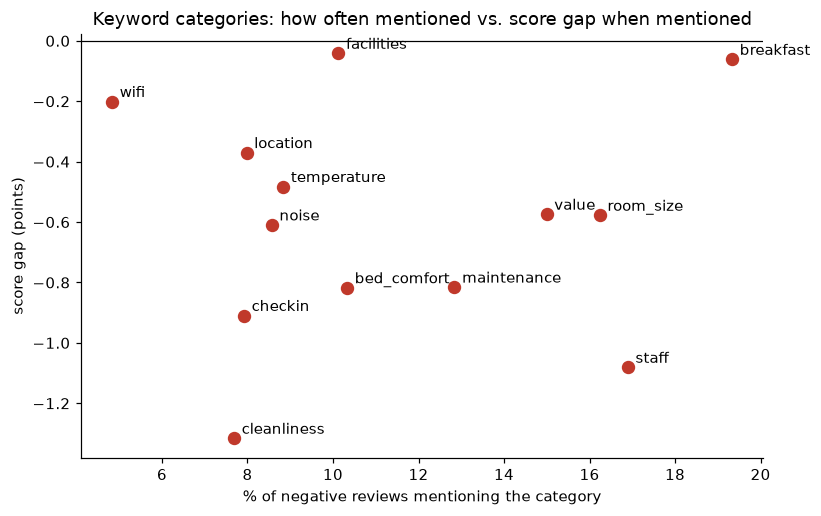

In [18]:
# How common vs. how costly: the manager cares about both
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(cats["% of complaints mentioning"], cats["score gap"], s=60, color=LOW)
for cat, r in cats.iterrows():
    ax.annotate(cat, (r["% of complaints mentioning"], r["score gap"]), xytext=(5, 3), textcoords="offset points")
ax.axhline(0, color="black", lw=0.8)
ax.set(title="Keyword categories: how often mentioned vs. score gap when mentioned",
       xlabel="% of negative reviews mentioning the category", ylabel="score gap (points)")
plt.show()

In [19]:
# Does the picture change for business vs. leisure travelers? (score gap by trip type)
gaps = {}
for trip in ["Business", "Leisure"]:
    sub, f = has_neg[has_neg.Trip_Type == trip], flags[has_neg.Trip_Type == trip]
    gaps[trip] = {cat: sub.Reviewer_Score[f[cat] == 1].mean() - sub.Reviewer_Score[f[cat] == 0].mean() for cat in f}
pd.DataFrame(gaps).sort_values("Business").style.format("{:+.2f}")

,Business,Leisure
cleanliness,-1.19,-1.33
staff,-1.02,-1.08
maintenance,-0.89,-0.78
bed_comfort,-0.89,-0.84
checkin,-0.82,-0.88
value,-0.76,-0.52
temperature,-0.63,-0.43
noise,-0.53,-0.61
room_size,-0.47,-0.60
wifi,-0.44,-0.09


The most important result so far. How often a complaint is mentioned and how much it costs are different things.
- Breakfast is the most common complaint (19.3% of complaints) but costs almost nothing (-0.06 points). Facilities (bar, pool, minibar) are similar (10.1%, -0.04). Guests mention them, but they still give high scores.
- Cleanliness is less common (7.7%) but has the biggest gap: -1.32 points. Check-in/booking problems (-0.91), bed comfort (-0.82) and maintenance (-0.82) are next.
- Staff is both common (16.9%) and costly (-1.08), so it is the strongest early candidate for the top of the fix list.

Business vs. leisure: the order is mostly the same (cleanliness and staff on top for both). But value (-0.76 vs. -0.52), Wi-Fi (-0.44 vs. -0.09) and temperature (-0.63 vs. -0.43) cost business travelers more, while room size and noise cost leisure travelers a bit more. That fits a guest who is working from the room and not paying out of pocket for leisure.

These are raw gaps from rough keywords. A review that mentions three things counts in all three gaps, and there are no controls for city, trip type or nationality. Phase 3 replaces the keywords with Claude labels and the gaps with a regression.

### 2.5 Baseline sentiment: VADER

VADER scores each box separately. Two checks, from the Homework 2 feedback:
1. Does VADER agree with the real score? Correlation between VADER's compound score and `Reviewer_Score` (Pearson for the linear relationship, Spearman because the score is skewed).
2. What does "neutral" mean? VADER only adds up the scores of words in its lexicon, so a compound of exactly 0 means either no lexicon word was found or positive and negative words cancelled out.

In [20]:
# Step 2.5: VADER on the negative and positive boxes (reviews with real text only)
neg_v = vader_table(df.loc[df.has_neg == 1, "neg_clean"])
pos_v = vader_table(df.loc[df.has_pos == 1, "pos_clean"])
df["neg_vader"], df["pos_vader"] = neg_v.compound, pos_v.compound

corr = pd.DataFrame({
    "Pearson r": [df.neg_vader.corr(df.Reviewer_Score), df.pos_vader.corr(df.Reviewer_Score)],
    "Spearman rho": [df.neg_vader.corr(df.Reviewer_Score, method="spearman"),
                     df.pos_vader.corr(df.Reviewer_Score, method="spearman")],
    "reviews": [len(neg_v), len(pos_v)],
}, index=["VADER on negative box", "VADER on positive box"])
corr.style.format({"Pearson r": "{:.3f}", "Spearman rho": "{:.3f}"})

,Pearson r,Spearman rho,reviews
VADER on negative box,0.275,0.259,13738
VADER on positive box,0.364,0.344,18506


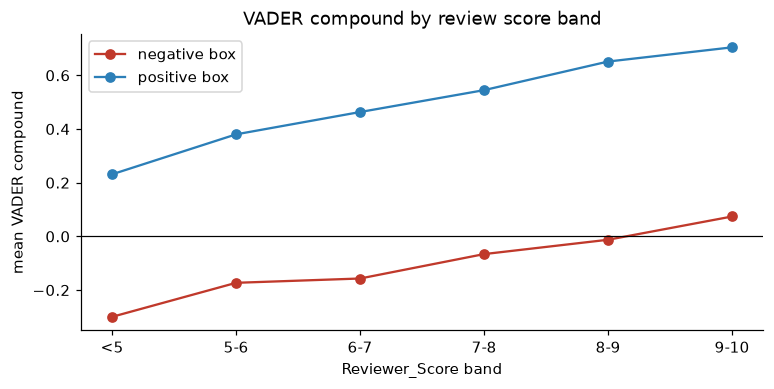

Reviewer_Score,<5,5-6,6-7,7-8,8-9,9-10
neg_vader,-0.300,-0.173,-0.157,-0.066,-0.013,0.074
pos_vader,0.231,0.380,0.463,0.545,0.651,0.704


In [21]:
# Mean VADER score by review score band
bands = pd.cut(df.Reviewer_Score, [0, 5, 6, 7, 8, 9, 10], labels=["<5", "5-6", "6-7", "7-8", "8-9", "9-10"])
by_band = df.groupby(bands, observed=True)[["neg_vader", "pos_vader"]].mean()
ax = by_band.plot(marker="o", color=[LOW, HIGH], figsize=(8, 3.5))
ax.axhline(0, color="black", lw=0.8)
ax.set(title="VADER compound by review score band", xlabel="Reviewer_Score band", ylabel="mean VADER compound")
ax.legend(["negative box", "positive box"]); plt.show()
by_band.round(3).T

In [22]:
# Why are neutral scores neutral? And how often does VADER call a COMPLAINT positive?
reasons = pd.DataFrame({"negative box": neg_v.neutral_reason.value_counts(normalize=True),
                        "positive box": pos_v.neutral_reason.value_counts(normalize=True)})
display(reasons.style.format("{:.1%}"))
print(f"Negative-box texts that VADER scores as positive (compound > 0.05): {(neg_v.compound > 0.05).mean():.1%}")

,negative box,positive box
neutral_reason,,
not neutral,70.2%,84.8%
no lexicon words,29.7%,15.2%
words cancel out,0.1%,0.0%


Negative-box texts that VADER scores as positive (compound > 0.05): 28.5%


In [23]:
# Examples: complaints from LOW-score reviews that VADER thinks are positive
fooled = df[(df.Low_Score == 1) & (df.neg_vader > 0.5) & df.neg_words.between(6, 40)]
fooled.sort_values("neg_vader", ascending=False)[["Reviewer_Score", "neg_vader", "neg_clean"]].head(6)

,Reviewer_Score,neg_vader,neg_clean
1105,6.3,0.9062,4day stay 3rooms 1st room dirty and smell Upgrade room good but only 2 days 3rd room smell from apartment below cook...
17646,6.7,0.8832,Staff were a bit too cool to provide good service especially during breakfast one day they were more interested in t...
15028,5.8,0.8779,It would be great if they renovate the hotel and work on the interior design And train the staff on keeping the smil...
14848,5.4,0.8720,very small room decent but now super clean
14057,5.4,0.8555,Room overlooked by two floors of office workers Overall hotel was pretty naff felt like a pimped up Lots of office p...
8339,5.4,0.8442,Totally commercial hotel due to its huge size and you don t feel welcomed or served with good hospitality None of th...


#### What I see
- VADER agrees with the true score only weakly to moderately: r = 0.28 on the negative box and 0.36 on the positive box (Spearman is about the same). The two scales are different (VADER -1 to +1, review score 2.5 to 10), which is why I compare them with a correlation, as suggested in the Homework 2 feedback. The trend by score band is in the right direction (negative box: -0.30 for scores under 5 up to +0.07 for 9-10), but the spread inside each band is large.
- "Neutral" almost always means VADER found nothing to score: 29.7% of real complaints contain no VADER lexicon word ("room small", "no kettle", "lift out of order"). Only 0.1% are neutral because positive and negative words cancel out. So a neutral score here means the complaint has no emotional words, not that it is mild.
- 28.5% of complaints get a positive VADER score. Guests write complaints with polite, positive words: "it would be great if they renovate", "Staff were a bit too cool to provide good service", "decent but now super clean" (a typo for "not"). VADER only adds up the words, so it misses the sentence's meaning.

For the project: VADER measures tone, not what went wrong, so it can't produce a fix list. I'll keep it only as a baseline to compare against.

### 2.6 Topic modeling (LDA) on low-score complaints

Is the complaint category list missing anything? LDA on the negative box of low-score reviews finds word groups without being told the categories. (The topics are only used to check the category list; they are not model features.)

In [24]:
# Step 2.6: LDA with 10 topics on low-score complaints
lda_vec = CountVectorizer(preprocessor=clean_review, stop_words=STOP_WORDS + ["hotel", "room", "rooms", "stay"],
                          min_df=10, max_df=0.5)
counts = lda_vec.fit_transform(low_neg)
lda = LatentDirichletAllocation(n_components=10, random_state=42, learning_method="batch", max_iter=30)
doc_topics = lda.fit_transform(counts)

vocab = lda_vec.get_feature_names_out()
topics = pd.DataFrame({
    "top words": [", ".join(vocab[i] for i in comp.argsort()[::-1][:10]) for comp in lda.components_],
    "share of reviews (dominant)": pd.Series(doc_topics.argmax(axis=1)).value_counts(normalize=True).sort_index().values,
})
topics.style.format({"share of reviews (dominant)": "{:.1%}"})

,top words,share of reviews (dominant)
0,"not, old, clean, floor, dirty, properly, bed, needs, furniture, carpet",12.7%
1,"no, not, small, bathroom, coffee, tea, shower, bar, space, pool",10.9%
2,"bathroom, shower, small, water, cold, no, hot, bed, door, bath",10.0%
3,"staff, breakfast, not, service, poor, small, bed, expensive, restaurant, good",13.9%
4,"not, booking, day, check, breakfast, booked, no, time, staff, com",10.7%
5,"no, staff, told, check, asked, time, just, bed, not, reception",10.4%
6,"air, window, noisy, noise, work, conditioning, night, small, hot, no",7.3%
7,"not, star, beds, small, standard, like, far, city, need, double",7.5%
8,"price, not, breakfast, location, money, parking, paid, worth, expensive, little",8.5%
9,"not, staff, reception, door, like, told, people, pay, card, asked",7.9%


What I see. LDA found ten topics in low-score complaints. Most of them match my complaint categories, which is a good sign: dirty and old rooms (0, cleanliness + maintenance), bathroom and hot/cold water (2), staff and restaurant service (3), booking and check-in (4, 5), air conditioning + window + noise (6), and price/worth/parking (8, value).

It also showed what my first category list was missing:
- Topic 1 (coffee, tea, bar, pool, space): complaints about hotel facilities that are closed, missing or cost extra. There was no category for these.
- Topic 7 (star, beds, standard, double): guests judging the hotel against its star rating, and getting a different bed or room than they booked.
- Topic 6 mixes temperature and noise: guests open the window because the AC is broken, then hear the street. The two complaints occur together, so the regression must include both to separate them.

Based on this, the category list now has a `facilities` category, `checkin` covers "booking not honored", and `value` covers "not up to its star rating" (Section 3).

LDA is unstable. When I removed about 130 more placeholder reviews (Section 1.1), the ten topics came out noticeably different, even with the same random seed. The facilities and star-rating topics showed up both times, so the changes to the category list hold up. But this is one more reason not to use the topics as features: they are mixtures, they shift with small changes in the data, and names like "topic 7" are hard to explain to a manager.

## 3. Claude: sample prompts for complaint labeling

The plan for Phase 3 is to have Claude tag complaint categories (multi-label) in the negative box. Here I tried the prompt on 12 reviews (6 low-score, 6 high-score, random), using Claude Haiku 5.5 at low effort with a JSON schema, so the answer is always a list of categories from my list. Following the Class 13 case:
- Claude must quote the evidence for each category, which makes it easy to check and to explain.
- The text sent is the NER-cleaned text (staff names removed).
- Results are saved to `data/claude_sample_labels.jsonl`, so re-running the notebook does not call the API again. Anyone without an API key can still run it.

Prompt revisions so far. My first category list (v1) had no category for hotel facilities, and `checkin` did not cover bookings. In the first trial run, Claude put "The rooftop bar was not open during off season" and "Air con ... broken in the bar" under `breakfast` (food and drink), because "bar" was the closest fit. LDA topics 1 and 7 in Section 2.6 pointed to the same gaps (coffee, tea, bar, pool; star, beds, double). So v2, used below, adds `facilities` and widens `checkin` to "the booking was not honored". Topic 7 ("star, beds, small, standard") also showed guests judging the hotel against its star rating, so `value` now includes "not up to the hotel's star rating". The v1 labels were thrown away; the cache only reuses labels made with the current categories and definitions.

In [25]:
print(prompt_label.format(categories="\n".join(f"- {k}: {v}" for k, v in CATEGORIES.items()),
                          review="(negative review text goes here)"))

You are labeling hotel guest reviews for a hotel group's guest experience manager.
Below is what one guest wrote in the "What did you dislike?" box. Tag every complaint category that applies.

Categories:
- cleanliness: dirt, stains, dust, hair, bad smells, mould, or poor housekeeping
- noise: noise from the street, other guests, thin walls, construction, or the building
- staff: rude, unhelpful, or slow staff, or poor service from reception or other staff
- room_size: the room or bathroom is small, cramped, or has no space for luggage
- breakfast: breakfast, restaurant, or other food and drink served at the hotel
- facilities: hotel facilities missing, closed, or extra cost: bar, pool, gym, spa, minibar, parking, kettle
- value: price too high for what you get, unexpected charges or extra fees, or not up to the hotel's star rating
- maintenance: broken, worn, or outdated things: shower, plumbing, lift, furniture, decor
- temperature: room too hot or too cold, air conditioning or heati

In [26]:
# Step 3: Label 12 negative reviews (cached after the first run)
# The 12 trial reviews (6 low, 6 high) were drawn at random once; their ids are saved in the label file
cache = Path.cwd().parent / "data" / "claude_sample_labels.jsonl"
trial_ids = [json.loads(line)["review_id"] for line in open(cache, encoding="utf-8")]
trial = has_neg[has_neg.review_id.isin(trial_ids)]
assert len(trial) == 12 and trial.Low_Score.sum() == 6
results = label_with_cache(trial, cache, text_col="neg_clean")
trial = trial.assign(claude=[r["complaints"] for r in results], cost=[r["cost_usd"] for r in results])
trial["claude_categories"] = trial.claude.map(lambda cs: ", ".join(sorted({c["category"] for c in cs})) or "(none)")
kw = keyword_flags(trial.neg_clean)
trial["keyword_categories"] = kw.apply(lambda r: ", ".join(c for c in kw.columns if r[c]) or "(none)", axis=1)
print(f"Cost of these 12 calls: ${trial.cost.sum():.4f} (about ${trial.cost.mean():.5f} per review)")
trial[["Reviewer_Score", "neg_clean", "claude_categories", "keyword_categories"]]

12 labels reused from cache, 0 new API calls
Cost of these 12 calls: $0.0018 (about $0.00015 per review)


,Reviewer_Score,neg_clean,claude_categories,keyword_categories
824,4.6,Reception slow and male staff grumpy Failed to clean room one day but someone had been in room to put clean towels i...,"cleanliness, facilities, staff","cleanliness, staff, bed_comfort"
2054,5.8,Staff customer service awful,staff,staff
3573,9.6,Need instructions on how to make shower work,maintenance,maintenance
4530,8.8,The rooftop bar was not open during off season which is a real shame many guests tried to gain access to it,facilities,facilities
6069,4.2,Very overpriced for a basic single room regardless of London prices Surrounding area has rubbish everywhere,"location, value","value, location"
7605,3.8,Door to bathroom wouldn t close lock Lamp was broken tv was broken Towel rail was hanging off the wall in the bathro...,"maintenance, noise, temperature","noise, maintenance, temperature"
9199,8.8,Some of the ground me floor restaurant staff didn t have the best of attitudes,staff,"staff, breakfast"
9572,8.8,Air con too hot where broken in the bar but too cold in the downstairs bar where it was working,"facilities, temperature","facilities, maintenance, temperature"
13318,6.7,The price was hiked up for the game and for that price breakfast should be included,"breakfast, value","breakfast, value"
15684,7.5,Beds were 2 singles pushed together slightly outdated,"checkin, maintenance",bed_comfort


In [27]:
# Evidence check (as in the Class 13 case): does every quote appear in the review?
def norm(s):
    return " ".join(clean_review(s).split())
# An empty quote would "appear" in any review, so it has to count as not found
ev = [(row.Reviewer_Score, c["category"], c["evidence"], bool(norm(c["evidence"])) and norm(c["evidence"]) in norm(row.neg_clean))
      for row in trial.itertuples() for c in row.claude]
ev = pd.DataFrame(ev, columns=["score", "category", "evidence", "found in review"])
print(f"{ev['found in review'].mean():.0%} of {len(ev)} quotes appear in the review")
ev

100% of 25 quotes appear in the review


,score,category,evidence,found in review
0,4.6,staff,Reception slow and male staff grumpy,True
1,4.6,cleanliness,Failed to clean room one day,True
2,4.6,cleanliness,Rang reception and was told only clean every other day,True
3,4.6,cleanliness,was told only changed sheets every other day so was given wrong info,True
4,4.6,facilities,only 1 tea bag,True
5,5.8,staff,Staff customer service awful,True
6,9.6,maintenance,Need instructions on how to make shower work,True
7,8.8,facilities,The rooftop bar was not open during off season which is a real shame many guests tried to gain access to it,True
8,4.2,value,Very overpriced for a basic single room regardless of London prices,True
9,4.2,location,Surrounding area has rubbish everywhere,True


#### What I see
- Claude and the keyword lexicon agree on most of the 12 reviews, and all 25 evidence quotes appear word for word in the reviews.
- Claude did better where meaning matters. It caught "slightly outdated" (maintenance) and "Every things looks very simple for a 4 stars hotel" (value), which the keywords missed. It also avoided keyword false positives: "restaurant staff didn't have the best of attitudes" is a staff complaint, not breakfast, and "had to make own bed" is housekeeping, not bed comfort.
- Multi-label matters: "the heating makes noise" is correctly tagged both noise and temperature. Review 19178 has five different complaints.
- Claude's errors come from overlapping definitions. "Beds were 2 singles pushed together" was tagged `checkin` (booking not honored). That is only right if the guest booked a double; I would have said `bed_comfort`. "Air con ... broken in the bar" got `temperature` even though the definition is about the room. These are the cases the hand check will measure.
- Cost: $0.0018 for 12 calls, about $0.00015 per review, so a 3,000-review sample is about $0.45 (about half that with the Batch API).

## 4. Plan for Phase 3

### 4.1 Which path, and what changed since Phase 1

Path A, but focused on explaining the score, not predicting it. Every review already has its score, so a classifier that predicts "low score" from text would only tell the manager what they already know. The business question is which complaints cost the most points, so that the manager knows what to fix first. The model is:

`Reviewer_Score ~ complaint flags + praise flags + controls (City, Trip_Type, Nationality, Nights, review month)`

Each complaint coefficient = points lost when a guest raises that complaint, holding the other complaints and the controls fixed. Points lost x how often the complaint occurs = expected points lost per 100 reviews. That gives a ranked fix list. Section 2.4 already shows why the ranking needs both numbers: breakfast is the most common complaint but costs almost nothing.

I'll also run a logistic regression on `Low_Score` (below 7) as a robustness check, because falling below 7 is where hotels lose ranking.

### 4.2 Positive and negative reviews: both, kept separate

I use both boxes but don't concatenate them. The box tells me the direction: "location" in the negative box is a complaint, and in the positive box it is praise. Merging them would mix the two. So:
- Complaint flags come from the negative box, and praise flags from the positive box, both labeled by Claude. Praise flags show what earns high scores (the feedback's suggestion).
- For the TF-IDF model, I fit two vectorizers (`neg_` and `pos_` features), not one on joined text.
- Claude labels each box on its meaning, which handles guests who paste a complaint into the positive box (Section 1.6).

### 4.3 TF-IDF words and Claude categories: two separate models, compared

They are not in one model for interpretation. "dirty" and `cleanliness` measure the same thing, so in a joint model they would split the effect between them and neither coefficient would make sense. Instead, all models use the same train/test split and the same controls:

| Model | Features | Purpose |
|---|---|---|
| M0 | controls only | baseline |
| M1 | controls + complaint and praise flags (about 28) | the fix list |
| M2 | controls + TF-IDF on both boxes (thousands), ridge | benchmark: how much can text explain? |
| M3 | M1 + M2 | what the categories miss (incremental R² only) |

Does a higher R² mean TF-IDF is the better model? No. I expect M2 to have the higher R², because thousands of features can fit noise and pick up intensity and length ("worst", "rude", long reviews), as in Sections 1.5 and 2.3. To compare fairly:
1. Use out-of-sample R² and RMSE on a held-out test set and 5-fold cross-validation, not in-sample R², which always rises with more features. Also report adjusted R² for the linear models.
2. Compute the share of explainable variation the categories capture: (R²_M1 - R²_M0) / (R²_M2 - R²_M0). If 28 named categories capture, say, 70% of what 2,000 words capture, the categories are the better tool for the manager.
3. Compare usefulness: M1 gives 13 numbers a manager can act on; M2's top words are mostly "poor" and "bad".
4. Check stability: whether M1's ranking holds across cross-validation folds, trip types and cities.

### 4.4 Predict the rating, the complaint type, or both?

Claude measures the complaint type, and the regression explains the rating. Neither one is a prediction task for its own sake. Complaint labeling is a measurement problem, and I check its accuracy by hand. The rating model is judged by how well it explains and whether its coefficients are stable, not by how well it would predict a new review.

### 4.5 Claude labeling plan

- Sample: about 3,000 reviews from the full 515K, stratified by City x Trip_Type (6 x 2 cells, about 250 each), so business travelers and smaller cities have enough reviews for the subgroup checks. Because this oversamples some cells, the "how often" part of the fix list uses the real shares from the full data (or sample weights).
- What Claude does: tags every complaint category in the negative box and every praise category in the positive box (multi-label), with an evidence quote for each. It uses `claude-haiku-5-5` at low effort with a JSON schema limited to my categories, on NER-cleaned text. Reviews with a placeholder box get all zeros without an API call.
- Batch API: the 3,000 x 2 boxes go as one batch at half price. Estimated cost: under $1 (measured $0.00015 per box in Section 3).
- Route (1): use the labeled sample directly, with no separate classifier. 3,000 reviews is plenty for about 28 flags plus controls, and a classifier trained on Claude's labels would add a second layer of error. If time allows, I'll try a zero-shot Hugging Face model (from the pipelines homework) on the same sample as a comparison, but it's not required for the answer.

### 4.6 Checking the labels

1. Hand-check about 100 labeled reviews (spread over categories, cities, and low/high scores). Report per-category precision and recall against my labels. The Class 13 case showed which errors to look for: negation ("Sorry, no pets!" tagged as pet-friendly) and overlapping definitions ("2 singles pushed together").
2. Evidence check: every quote must appear in the review (100% so far).
3. Consistency: send about 50 reviews twice. In Class 13, Claude tagged identical text differently, so I need to know how often that happens here.
4. Keyword cross-check: compare with the keyword lexicon. Large disagreements show where a definition needs work.

### 4.7 Segments and controls

- Nationality is a control, not a driver (Section 1.4: almost a 0.9-point gap between groups).
- Business vs. leisure and city: fit M1 with complaint x trip-type interactions, and separately by city. Compare the rankings with a Spearman rank correlation. Section 2.4 suggests value, Wi-Fi and temperature matter more to business travelers.
- Length: report M1 with and without the negative word count, to show the complaint coefficients are not just "long angry review" (Section 1.5).

### 4.8 Concerns

- Validity of LLM labels: measured by the hand check, evidence check and consistency test above. Categories with poor precision will be merged or dropped before modeling.
- Causality: a coefficient is an association. Unhappy guests may complain about more things (a halo effect), so "cleanliness costs 1.3 points" is an upper bound on what fixing cleanliness would recover. As a robustness check I'll add hotel fixed effects, which compares guests within the same hotel.
- Privacy: the reviews are public, but staff names are removed with NER before any text goes to the API (Section 2.1). No reviewer identifiers are sent. The API key stays in `.env`, which `.gitignore` excludes.
- Scale and tokens: small. About 6,000 short texts at about 1,000 tokens each, under $1 with batching.
- Data limits: only guests who chose to write a review, Booking.com's scale starts at 2.5, the data is from 2015 to 2017, and London is half the reviews. A small number of reviews are not in English.